# Sonar Rock vs. Mine Classification: Ten Classifiers With and Without PCA

This notebook reproduces every table and every data-based figure in the paper *"Ten Classifiers With and Without PCA for Sonar Mine-versus-Rock Discrimination on the UCI Benchmark"* (Al-Shammari, Alazmi, and Al-Shammari, University of Ha'il).

**What it does.** Ten classifiers are evaluated on the UCI Sonar dataset (208 returns, 60 frequency-band energies, 111 mines and 97 rocks), each with and without principal component analysis (PCA). Every step that learns from data, including the scaler, the PCA, hyperparameter tuning, and decision thresholds, is fitted on training data or training folds only, so no information from the test data reaches the model.

**How the notebook is organized.** The sections follow the paper:

1. Data, Table 1, and the dependence between neighboring returns
2. Table 2: the ten classifiers and their fixed settings
3. Table 3: nested cross-validation, the primary result
4. Tables 4 and 5: repeated cross-validation with eight components, eight whitened components, and all 60 features
5. Tables 6 and 7: ROC AUC, average precision, and cost-sensitive decision thresholds
6. The component sweep (Figure 6)
7. Blocked cross-validation
8. Tables 8 and 9: the 85/15 hold-out split
9. Table A1: the exploratory pipelines of Appendix A
10. Figures 2 to 8, each in its own cell and saved to the `figures` folder

**Before you run it.** Install the versions in `requirements.txt` and keep `sonar_data.csv` in the same folder as the notebook. A full run takes about 90 minutes: the nested cross-validation needs about 40 minutes, Table A1 about 15, and the rest about 30. All random seeds are fixed, so the printed numbers should match the paper exactly. Figure 1 is an illustration and is not produced by the code.

In [1]:
import os
import time
import warnings
from collections import Counter
import numpy as np
import pandas as pd
import scipy, sklearn, xgboost
from scipy import stats
from scipy.stats import binomtest
from sklearn.base import clone
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, roc_auc_score, average_precision_score, precision_recall_curve
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
print("numpy", np.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)

numpy 2.5.3 | scipy 1.18.1 | scikit-learn 1.9.1 | xgboost 3.2.0


## 1. Data, Table 1, and the dependence check

The data are loaded and the labels encoded (Mine = 0, Rock = 1). The stratified 85/15 hold-out split (176 training and 32 test returns) gives Table 1. The second cell measures how similar neighboring rows of the file are, which motivates the blocked cross-validation, and reports the variance carried by the principal components.

In [2]:
path = "sonar_data.csv" if os.path.exists("sonar_data.csv") else r"D:\DataMining\sonar_data.csv"
df = pd.read_csv(path)
X = df.drop("target", axis=1).to_numpy(float)
le = LabelEncoder()
y = le.fit_transform(df["target"])
print(dict(zip(le.classes_, le.transform(le.classes_))))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=42)

table1 = pd.DataFrame({
    "Returns": [len(y_train), len(y_test), len(y)],
    "Share (%)": [round(100 * len(y_train) / len(y), 1), round(100 * len(y_test) / len(y), 1), 100.0],
    "Mines (M)": [(y_train == 0).sum(), (y_test == 0).sum(), (y == 0).sum()],
    "Rocks (R)": [(y_train == 1).sum(), (y_test == 1).sum(), (y == 1).sum()],
}, index=["Training set", "Test set", "Full dataset"])
table1

{'M': np.int64(0), 'R': np.int64(1)}


,Returns,Share (%),Mines (M),Rocks (R)
Training set,176,84.6,94,82
Test set,32,15.4,17,15
Full dataset,208,100.0,111,97


In [3]:
labels = df["target"].to_numpy()
for c in ["R", "M"]:
    Z = X[labels == c]
    consecutive = np.linalg.norm(Z[1:] - Z[:-1], axis=1).mean()
    others = np.mean([np.linalg.norm(Z[i] - Z[j]) for i in range(len(Z)) for j in range(i + 2, len(Z))])
    print(f"{c}: consecutive {consecutive:.3f}  non-adjacent {others:.3f}  ratio {consecutive / others:.2f}")

D = np.linalg.norm(X[:, None, :] - X[None, :, :], axis=2)
np.fill_diagonal(D, np.inf)
nearest = D.argmin(axis=1)
print(f"Nearest other return is an adjacent row for {100 * (np.abs(nearest - np.arange(len(X))) == 1).mean():.1f}% of the returns")

Str = StandardScaler().fit(X_train).transform(X_train)
ratio = PCA().fit(Str).explained_variance_ratio_
print(f"PC1 {100 * ratio[0]:.1f}%  first 8 {100 * ratio[:8].sum():.1f}%  mean of first 8 {100 * ratio[:8].mean():.1f}%")
print("Maximum of features 49 to 59:", X[:, 49:60].max(axis=0).round(3))

R: consecutive 1.202  non-adjacent 1.809  ratio 0.66
M: consecutive 0.898  non-adjacent 1.775  ratio 0.51
Nearest other return is an adjacent row for 40.4% of the returns
PC1 20.8%  first 8 69.6%  mean of first 8 8.7%
Maximum of features 49 to 59: [0.082 0.1   0.071 0.039 0.035 0.045 0.039 0.036 0.044 0.036 0.044]


## 2. Table 2: classifiers, settings, and helper functions

This cell defines the ten classifiers with the fixed settings of Table 2, the pipeline (scaler, optional PCA, classifier), and the statistical helpers: the corrected repeated k-fold t-test, the Holm adjustment, Wilson intervals, and the exact McNemar test. It also checks that the MLP converges well within its 2000-iteration limit.

In [4]:
def make_models():
    return {
        "SVM": SVC(probability=True, kernel="rbf", C=2, random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=120, max_depth=5, random_state=42),
        "MLP": MLPClassifier(max_iter=2000, random_state=42),
        "Extra Trees": ExtraTreesClassifier(n_estimators=120, max_depth=5, random_state=42),
        "XGBoost": XGBClassifier(n_estimators=120, learning_rate=0.12, max_depth=2, subsample=0.8,
                                 colsample_bytree=0.8, random_state=42, n_jobs=1),
        "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
        "Gradient Boosting": GradientBoostingClassifier(n_estimators=120, learning_rate=0.1, max_depth=3, random_state=42),
        "Logistic Regression": LogisticRegression(),
        "AdaBoost": AdaBoostClassifier(n_estimators=120, learning_rate=0.1, random_state=42),
        "Gaussian Naive Bayes": GaussianNB(),
    }

def pipe(model, k, whiten=False):
    steps = [("scaler", StandardScaler())]
    if k:
        steps.append(("pca", PCA(n_components=k, whiten=whiten)))
    steps.append(("clf", clone(model)))
    return Pipeline(steps)

def fold_scores(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    return (100 * (y_true == y_pred).mean(), 100 * cm[0, 0] / cm[0].sum(), 100 * cm[1, 0] / cm[1].sum(), int(cm[0, 1]), int(cm[1, 0]))

def corrected_ttest(diff, n_train, n_test):
    d = np.asarray(diff, float)
    var = d.var(ddof=1)
    if var == 0:
        return 1.0
    t = d.mean() / np.sqrt((1 / len(d) + n_test / n_train) * var)
    return 2 * stats.t.sf(abs(t), df=len(d) - 1)

def holm(pvalues):
    p = np.asarray(pvalues, float)
    order = np.argsort(p)
    adjusted = np.empty(len(p))
    running = 0.0
    for i, idx in enumerate(order):
        running = max(running, min(1.0, (len(p) - i) * p[idx]))
        adjusted[idx] = running
    return adjusted

def wilson(correct, n, z=1.959964):
    p = correct / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return 100 * (centre - half), 100 * (centre + half)

def mcnemar_exact(pred_a, pred_b, y_true):
    a_only = int(((pred_a == y_true) & (pred_b != y_true)).sum())
    b_only = int(((pred_a != y_true) & (pred_b == y_true)).sum())
    n = a_only + b_only
    return binomtest(min(a_only, b_only), n, 0.5).pvalue if n else 1.0

names = list(make_models())
for k in (8, None):
    mlp = pipe(make_models()["MLP"], k).fit(X_train, y_train)[-1]
    print(f"MLP on {'8 components' if k else '60 features'}: {mlp.n_iter_} iterations (limit 2000)")

MLP on 8 components: 687 iterations (limit 2000)
MLP on 60 features: 247 iterations (limit 2000)


## 3. Table 3: nested cross-validation (primary result, about 40 minutes)

The outer loop (5 folds, repeated 3 times) estimates performance. Inside each outer training fold, a 5-fold grid search chooses the hyperparameters and the number of principal components (5, 8, 12, 20, or none). The outer test folds are never used for any choice.

In [5]:
grids = {
    "SVM": (SVC(kernel="rbf", random_state=42),
            {"clf__C": [0.5, 1, 2, 5, 10, 50], "clf__gamma": ["scale", 0.005, 0.01, 0.05, 0.1]}),
    "Random Forest": (RandomForestClassifier(n_estimators=200, random_state=42),
                      {"clf__max_depth": [None, 5, 10], "clf__max_features": ["sqrt", 0.3]}),
    "MLP": (MLPClassifier(max_iter=2000, random_state=42),
            {"clf__hidden_layer_sizes": [(50,), (100,), (100, 50)], "clf__alpha": [1e-4, 1e-3, 1e-2, 1e-1]}),
    "Extra Trees": (ExtraTreesClassifier(n_estimators=200, random_state=42),
                    {"clf__max_depth": [None, 5, 10], "clf__max_features": ["sqrt", 0.3]}),
    "XGBoost": (XGBClassifier(subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=1),
                {"clf__n_estimators": [100, 300], "clf__max_depth": [2, 4], "clf__learning_rate": [0.05, 0.1]}),
    "K-Nearest Neighbors": (KNeighborsClassifier(),
                            {"clf__n_neighbors": [1, 3, 5, 7, 9], "clf__weights": ["uniform", "distance"]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=42),
                          {"clf__n_estimators": [100, 200], "clf__max_depth": [2, 3], "clf__learning_rate": [0.05, 0.1]}),
    "Logistic Regression": (LogisticRegression(max_iter=5000), {"clf__C": [0.01, 0.1, 1, 10, 100]}),
    "AdaBoost": (AdaBoostClassifier(random_state=42),
                 {"clf__n_estimators": [100, 300], "clf__learning_rate": [0.1, 0.5, 1.0]}),
    "Gaussian Naive Bayes": (GaussianNB(), {"clf__var_smoothing": [1e-9, 1e-6, 1e-3, 1e-1]}),
}
pca_options = [PCA(n_components=k) for k in [5, 8, 12, 20]] + ["passthrough"]

outer = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7).split(X, y))
start = time.time()
rows = []
for name, (est, grid) in grids.items():
    p = Pipeline([("scaler", StandardScaler()), ("pca", PCA()), ("clf", est)])
    scores, chosen, settings = [], Counter(), Counter()
    for i, (tr, te) in enumerate(outer):
        gs = GridSearchCV(p, dict(grid, pca=pca_options), cv=StratifiedKFold(5, shuffle=True, random_state=i),
                          scoring="accuracy", n_jobs=-1).fit(X[tr], y[tr])
        scores.append(fold_scores(y[te], gs.predict(X[te])))
        best = dict(gs.best_params_)
        chosen[getattr(best.pop("pca"), "n_components", "none")] += 1
        settings[str(sorted((k.replace("clf__", ""), v) for k, v in best.items()))] += 1
    s = np.array(scores)
    rows.append({"Model": name,
                 "Nested acc": f"{s[:, 0].mean():.2f} ± {s[:, 0].std(ddof=1):.2f}",
                 "Mine recall": round(s[:, 1].mean(), 2),
                 "False alarm": round(s[:, 2].mean(), 2),
                 "PCA chosen": f"{len(outer) - chosen['none']}/{len(outer)}",
                 "Components chosen": dict(chosen),
                 "Most chosen settings": settings.most_common(1)[0][0],
                 "_acc": s[:, 0].mean()})
    print(f"{name} done ({time.time() - start:.0f} s)")
table3 = pd.DataFrame(rows).sort_values("_acc", ascending=False)
print(table3.drop(columns="_acc").to_string(index=False))
print(f"\nMean: accuracy {table3['_acc'].mean():.2f}%  mine recall {table3['Mine recall'].mean():.2f}%  false alarm {table3['False alarm'].mean():.2f}%")

SVM done (33 s)


Random Forest done (255 s)


MLP done (670 s)


Extra Trees done (828 s)


XGBoost done (881 s)


K-Nearest Neighbors done (891 s)


Gradient Boosting done (1071 s)


Logistic Regression done (1078 s)


AdaBoost done (1390 s)


Gaussian Naive Bayes done (1394 s)
               Model   Nested acc  Mine recall  False alarm PCA chosen                      Components chosen                                               Most chosen settings
         Extra Trees 87.17 ± 3.93        90.69        16.79       4/15             {12: 2, 'none': 11, 20: 2}                       [('max_depth', None), ('max_features', 0.3)]
                 SVM 86.19 ± 4.93        88.59        16.51       9/15        {12: 3, 'none': 6, 20: 5, 5: 1}                                     [('C', 5), ('gamma', 'scale')]
 K-Nearest Neighbors 84.14 ± 4.51        87.34        19.58      13/15  {12: 5, 20: 5, 'none': 2, 8: 1, 5: 2}                       [('n_neighbors', 1), ('weights', 'uniform')]
                 MLP 83.96 ± 6.30        85.23        17.49      12/15  {5: 5, 'none': 3, 20: 4, 12: 2, 8: 1}                [('alpha', 0.0001), ('hidden_layer_sizes', (100,))]
             XGBoost 83.15 ± 5.19        84.07        17.88       3/15          

## 4. Tables 4 and 5: repeated cross-validation with fixed settings

Each classifier is run with the settings of Table 2 on 50 test folds (5 folds, repeated 10 times), using eight components, eight whitened components, and all 60 features. The first cell gives the accuracies of Table 4, and the second gives the mine recall and false alarm rates of Table 5. Differences are tested with the corrected t-test and adjusted with the Holm procedure.

In [6]:
folds = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42).split(X, y))
n_tr, n_te = len(folds[0][0]), len(folds[0][1])
reps = {"pca8": (8, False), "white8": (8, True), "none": (None, False)}
start = time.time()
res, probs = {}, {}
for name, model in make_models().items():
    for tag, (k, wh) in reps.items():
        sc, pm = [], []
        for tr, te in folds:
            p = pipe(model, k, wh).fit(X[tr], y[tr])
            sc.append(fold_scores(y[te], p.predict(X[te])))
            if tag != "white8":
                pm.append(p.predict_proba(X[te])[:, 0])
        res[name, tag] = np.array(sc)
        probs[name, tag] = pm
    print(f"{name} done ({time.time() - start:.0f} s)")

def ttests(j, a, b):
    p = [corrected_ttest(res[n, a][:, j] - res[n, b][:, j], n_tr, n_te) for n in names]
    return np.array(p), holm(p)

p_acc, h_acc = ttests(0, "pca8", "none")
p_w, h_w = ttests(0, "white8", "pca8")
table4 = pd.DataFrame({
    "PCA (8)": [f"{res[n, 'pca8'][:, 0].mean():.2f} ± {res[n, 'pca8'][:, 0].std(ddof=1):.2f}" for n in names],
    "Whitened PCA (8)": [f"{res[n, 'white8'][:, 0].mean():.2f} ± {res[n, 'white8'][:, 0].std(ddof=1):.2f}" for n in names],
    "No PCA": [f"{res[n, 'none'][:, 0].mean():.2f} ± {res[n, 'none'][:, 0].std(ddof=1):.2f}" for n in names],
    "Delta": [round(res[n, "pca8"][:, 0].mean() - res[n, "none"][:, 0].mean(), 2) for n in names],
    "p": p_acc.round(3), "p Holm": h_acc.round(3),
    "Whitened - PCA": [round(res[n, "white8"][:, 0].mean() - res[n, "pca8"][:, 0].mean(), 2) for n in names],
    "p whitened": p_w.round(3),
    "_acc": [res[n, "pca8"][:, 0].mean() for n in names]}, index=names).sort_values("_acc", ascending=False)
print(table4.drop(columns="_acc").to_string())
m8, mw, m0 = [np.mean([res[n, t][:, 0].mean() for n in names]) for t in ("pca8", "white8", "none")]
print(f"\nMean accuracy: PCA {m8:.2f}%  whitened {mw:.2f}%  no PCA {m0:.2f}%  ratio {100 * m8 / m0:.1f}%")

SVM done (1 s)


Random Forest done (19 s)


MLP done (54 s)


Extra Trees done (67 s)


XGBoost done (71 s)


K-Nearest Neighbors done (71 s)


Gradient Boosting done (90 s)


Logistic Regression done (91 s)


AdaBoost done (119 s)


Gaussian Naive Bayes done (119 s)
                           PCA (8) Whitened PCA (8)        No PCA  Delta      p  p Holm  Whitened - PCA  p whitened
MLP                   83.80 ± 3.84     82.66 ± 5.44  86.94 ± 5.83  -3.13  0.309   1.000           -1.15       0.542
SVM                   82.85 ± 5.20     82.90 ± 6.39  86.45 ± 5.14  -3.61  0.193   1.000            0.05       0.978
K-Nearest Neighbors   82.75 ± 6.13     82.90 ± 6.02  81.25 ± 5.00   1.50  0.625   1.000            0.15       0.954
XGBoost               80.45 ± 5.34     80.45 ± 5.34  85.59 ± 4.98  -5.13  0.097   0.876            0.00       1.000
Random Forest         79.98 ± 6.79     79.98 ± 6.79  81.74 ± 5.68  -1.77  0.605   1.000            0.00       1.000
Extra Trees           79.97 ± 5.99     79.97 ± 5.99  83.31 ± 5.58  -3.34  0.340   1.000            0.00       1.000
Gradient Boosting     79.91 ± 6.41     79.91 ± 6.41  83.85 ± 6.53  -3.94  0.338   1.000            0.00       1.000
Gaussian Naive Bayes  75.78 ± 6.07    

In [7]:
p_rec, h_rec = ttests(1, "pca8", "none")
p_fa, h_fa = ttests(2, "pca8", "none")
table5 = pd.DataFrame({
    "Recall PCA": [res[n, "pca8"][:, 1].mean() for n in names], "Recall no PCA": [res[n, "none"][:, 1].mean() for n in names],
    "p rec": p_rec, "p rec Holm": h_rec,
    "FA PCA": [res[n, "pca8"][:, 2].mean() for n in names], "FA no PCA": [res[n, "none"][:, 2].mean() for n in names],
    "p FA": p_fa, "p FA Holm": h_fa}, index=names).loc[table4.index].round(3)
print(table5.to_string())
print("\nMean:", table5[["Recall PCA", "Recall no PCA", "FA PCA", "FA no PCA"]].mean().round(2).to_dict())
print("Mine recall lower with PCA for", int((table5["Recall PCA"] < table5["Recall no PCA"]).sum()), "of 10 models")

                      Recall PCA  Recall no PCA  p rec  p rec Holm  FA PCA  FA no PCA   p FA  p FA Holm
MLP                       85.040         90.822  0.154       0.615  17.637     17.532  0.983      1.000
SVM                       82.138         90.008  0.027       0.215  16.395     17.637  0.805      1.000
K-Nearest Neighbors       85.664         90.265  0.227       0.615  20.605     29.111  0.081      0.648
XGBoost                   79.893         88.498  0.098       0.492  19.000     17.763  0.818      1.000
Random Forest             78.162         89.727  0.037       0.258  18.026     27.411  0.037      0.329
Extra Trees               83.316         92.522  0.042       0.258  23.916     27.232  0.549      1.000
Gradient Boosting         79.704         87.395  0.164       0.615  19.932     20.226  0.962      1.000
Gaussian Naive Bayes      70.976         57.921  0.009       0.078  18.768     18.584  0.966      1.000
Logistic Regression       76.008         80.435  0.316       0.6

## 5. Tables 6 and 7: ranking quality and cost-sensitive thresholds

The first cell computes the ROC AUC and average precision for the mine class (Table 6). The second chooses a decision threshold inside every training fold for three costs of a missed mine relative to a false alarm (c = 1, 5, and 10), applies it to the test fold, and reports mine recall, false alarm rate, and expected cost (Table 7).

In [8]:
rows = []
for name in names:
    r = {"Model": name}
    for tag in ("none", "pca8"):
        r[f"ROC AUC {tag}"] = np.mean([roc_auc_score(y[te] == 0, s) for (tr, te), s in zip(folds, probs[name, tag])])
        r[f"AP {tag}"] = np.mean([average_precision_score(y[te] == 0, s) for (tr, te), s in zip(folds, probs[name, tag])])
    rows.append(r)
auc = pd.DataFrame(rows).set_index("Model").sort_values("ROC AUC none", ascending=False)
print(auc.round(3).to_string())
print("\nMean:", auc.mean().round(3).to_dict())

                      ROC AUC none  AP none  ROC AUC pca8  AP pca8
Model                                                             
SVM                          0.952    0.960         0.920    0.936
XGBoost                      0.935    0.946         0.884    0.908
MLP                          0.934    0.940         0.922    0.936
Extra Trees                  0.933    0.945         0.901    0.921
Random Forest                0.922    0.937         0.897    0.921
Gradient Boosting            0.919    0.933         0.887    0.912
K-Nearest Neighbors          0.914    0.904         0.910    0.905
AdaBoost                     0.884    0.908         0.834    0.856
Logistic Regression          0.858    0.875         0.824    0.839
Gaussian Naive Bayes         0.803    0.801         0.821    0.844

Mean: {'ROC AUC none': 0.905, 'AP none': 0.915, 'ROC AUC pca8': 0.88, 'AP pca8': 0.898}


In [9]:
costs = (1, 5, 10)
start = time.time()
rows = []
for name, model in make_models().items():
    for k, tag in ((None, "no PCA"), (8, "PCA (8)")):
        out = {c: [] for c in costs}
        for tr, te in folds:
            inner = cross_val_predict(pipe(model, k), X[tr], y[tr], cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 0]
            test = pipe(model, k).fit(X[tr], y[tr]).predict_proba(X[te])[:, 0]
            grid = np.unique(np.r_[0, inner, 1])
            for c in costs:
                cost = [c * ((inner < t) & (y[tr] == 0)).sum() + ((inner >= t) & (y[tr] == 1)).sum() for t in grid]
                t = grid[int(np.argmin(cost))]
                acc, rec, fa, missed, false_alarms = fold_scores(y[te], np.where(test >= t, 0, 1))
                out[c].append((acc, rec, fa, (c * missed + false_alarms) / len(te)))
        for c in costs:
            v = np.array(out[c])
            rows.append({"Model": name, "Input": tag, "c": c, "Accuracy": v[:, 0].mean(), "Mine recall": v[:, 1].mean(),
                         "False alarm": v[:, 2].mean(), "Cost": v[:, 3].mean()})
    print(f"{name} done ({time.time() - start:.0f} s)")
table6 = pd.DataFrame(rows).round(3)
for c in costs:
    print(f"\nTable 7, c = {c}")
    print(table6[table6.c == c].pivot(index="Model", columns="Input", values=["Mine recall", "False alarm", "Cost"]).round(3).to_string())
for c in costs:
    t = table6[table6.c == c].pivot(index="Model", columns="Input", values="Cost")
    print(f"c = {c}: lowest cost {t['no PCA'].idxmin()} {t['no PCA'].min():.3f}; lower without PCA for {(t['no PCA'] < t['PCA (8)']).sum()} of 10")

SVM done (5 s)


Random Forest done (70 s)


MLP done (166 s)


Extra Trees done (212 s)


XGBoost done (228 s)


K-Nearest Neighbors done (230 s)


Gradient Boosting done (310 s)


Logistic Regression done (313 s)


AdaBoost done (420 s)


Gaussian Naive Bayes done (422 s)

Table 7, c = 1
                     Mine recall         False alarm            Cost       
Input                    PCA (8)  no PCA     PCA (8)  no PCA PCA (8) no PCA
Model                                                                      
AdaBoost                  65.834  81.071      16.900  25.716   0.261  0.221
Extra Trees               77.439  86.198      17.347  19.516   0.201  0.164
Gaussian Naive Bayes      75.628  87.083      25.437  46.989   0.248  0.287
Gradient Boosting         77.075  83.640      17.721  19.079   0.205  0.176
K-Nearest Neighbors       82.889  82.866      21.589  17.842   0.192  0.174
Logistic Regression       75.787  83.656      27.258  30.089   0.256  0.227
MLP                       82.779  89.368      18.089  17.816   0.176  0.140
Random Forest             77.190  84.585      19.795  18.795   0.214  0.170
SVM                       78.996  87.391      12.953  12.905   0.173  0.127
XGBoost                   76.889  87.4

## 6. Component sweep (Figure 6)

Mean accuracy for 2 to 30 components and for all 60 features, using 5 folds repeated 5 times.

In [10]:
folds5 = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42).split(X, y))
counts = [2, 4, 6, 8, 10, 12, 15, 20, 30, None]
start = time.time()
sweep = {}
for name, model in make_models().items():
    sweep[name] = {str(k) if k else "all60": np.mean([100 * (pipe(model, k).fit(X[tr], y[tr]).predict(X[te]) == y[te]).mean() for tr, te in folds5]) for k in counts}
    print(f"{name} done ({time.time() - start:.0f} s)")
sweep = pd.DataFrame(sweep).T
sweep.loc["MEAN"] = sweep.mean()
sweep.round(2)

SVM done (2 s)


Random Forest done (30 s)


MLP done (89 s)


Extra Trees done (109 s)


XGBoost done (114 s)


K-Nearest Neighbors done (115 s)


Gradient Boosting done (142 s)


Logistic Regression done (143 s)


AdaBoost done (182 s)


Gaussian Naive Bayes done (183 s)


,2,4,6,8,10,12,15,20,30,all60
SVM,61.82,80.31,83.00,83.09,85.39,85.40,86.74,86.16,87.31,86.64
Random Forest,65.09,80.70,79.73,80.12,81.73,81.93,82.51,82.69,80.75,81.37
MLP,60.88,83.28,84.54,83.38,85.69,85.48,84.92,84.52,83.66,87.31
Extra Trees,63.63,80.30,78.85,80.79,82.01,82.11,81.24,80.46,79.13,82.97
XGBoost,60.97,77.80,78.19,80.59,80.78,81.34,81.54,81.26,79.53,85.77
K-Nearest Neighbors,62.01,78.97,82.31,82.51,83.47,83.17,83.76,83.55,81.91,81.81
Gradient Boosting,61.63,79.06,80.80,80.68,80.38,81.34,81.35,80.67,80.68,83.85
Logistic Regression,58.93,75.78,75.00,75.57,79.04,78.64,78.75,78.28,77.22,77.87
AdaBoost,65.39,73.48,73.48,73.38,73.86,73.96,74.15,74.15,74.15,79.43
Gaussian Naive Bayes,58.65,76.93,77.12,75.96,76.43,75.46,74.89,74.99,72.58,68.76


## 7. Blocked cross-validation

Each class is cut into five blocks of consecutive rows in the file order, and each pair of mine and rock blocks is held out once. Neighboring returns are thus kept largely out of the training data of the fold in which they are tested.

In [11]:
block = np.empty(len(y), int)
for c in (0, 1):
    for b, part in enumerate(np.array_split(np.where(y == c)[0], 5)):
        block[part] = b
blocked_folds = [(np.where(block != b)[0], np.where(block == b)[0]) for b in range(5)]

rows = []
for name, model in make_models().items():
    r = {k: np.array([fold_scores(y[te], pipe(model, k).fit(X[tr], y[tr]).predict(X[te])) for tr, te in blocked_folds]) for k in (8, None)}
    rows.append({"Model": name,
                 "Blocked PCA (8)": round(r[8][:, 0].mean(), 2), "Blocked no PCA": round(r[None][:, 0].mean(), 2),
                 "Mine recall PCA": round(r[8][:, 1].mean(), 2), "Mine recall no PCA": round(r[None][:, 1].mean(), 2)})
blocked = pd.DataFrame(rows)
print(blocked.to_string(index=False))
print("\nMean:", blocked.drop(columns="Model").mean().round(2).to_dict())

               Model  Blocked PCA (8)  Blocked no PCA  Mine recall PCA  Mine recall no PCA
                 SVM            64.46           63.49            60.59               59.57
       Random Forest            64.98           65.45            57.00               69.53
                 MLP            63.53           66.90            59.64               62.33
         Extra Trees            64.46           66.33            62.49               65.89
             XGBoost            64.47           74.64            59.68               76.01
 K-Nearest Neighbors            56.16           55.68            47.75               56.68
   Gradient Boosting            65.36           72.27            58.74               76.84
 Logistic Regression            64.54           63.65            62.49               63.40
            AdaBoost            65.53           70.27            56.25               70.40
Gaussian Naive Bayes            64.96           64.31            54.35               53.08

## 8. Tables 8 and 9: the 85/15 hold-out split

Results on the 32 test returns with eight components (Table 8), the Wilson intervals, McNemar tests, and rank correlations quoted in the text, and the comparison with and without PCA on the same returns (Table 9).

In [12]:
pred_pca, pred_raw, rows = {}, {}, []
for name, model in make_models().items():
    pred = pipe(model, 8).fit(X_train, y_train).predict(X_test)
    pred_pca[name] = pred
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, average="macro")
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    rows.append({"Model": name, "Acc (%)": round(100 * accuracy_score(y_test, pred), 2), "Prec (%)": round(100 * p, 2),
                 "Rec (%)": round(100 * r, 2), "F1 (%)": round(100 * f, 2), "Missed mines": int(cm[0, 1]), "False alarms": int(cm[1, 0])})
table8 = pd.DataFrame(rows).sort_values("Acc (%)", ascending=False, kind="stable").reset_index(drop=True)
table8

,Model,Acc (%),Prec (%),Rec (%),F1 (%),Missed mines,False alarms
0,SVM,96.88,96.88,97.06,96.87,1,0
1,Random Forest,90.62,90.87,90.39,90.54,1,2
2,Extra Trees,87.50,88.26,87.06,87.30,1,3
3,MLP,84.38,85.83,83.73,83.98,1,4
4,XGBoost,84.38,84.38,84.51,84.36,3,2
5,K-Nearest Neighbors,84.38,84.38,84.51,84.36,3,2
6,Gradient Boosting,81.25,81.78,80.78,80.95,2,4
7,Logistic Regression,78.12,78.17,77.84,77.93,3,4
8,AdaBoost,78.12,84.09,79.41,77.58,7,0
9,Gaussian Naive Bayes,71.88,72.62,72.35,71.85,6,3


In [13]:
n = len(y_test)
for name in ["SVM", "Random Forest"]:
    correct = int((pred_pca[name] == y_test).sum())
    lo, hi = wilson(correct, n)
    print(f"{name:14s} {correct}/{n}  95% Wilson interval {lo:.1f}% to {hi:.1f}%")
print(f"20 of 21: {wilson(20, 21)[0]:.1f}% to {wilson(20, 21)[1]:.1f}%")
print(f"McNemar SVM vs Random Forest: p = {mcnemar_exact(pred_pca['SVM'], pred_pca['Random Forest'], y_test):.3f}")

holdout = table8.set_index("Model")["Acc (%)"]
cv_pca = pd.Series({k: res[k, "pca8"][:, 0].mean() for k in names})
nested_acc = table3.set_index("Model")["_acc"]
print(f"Spearman hold-out vs repeated CV (PCA 8): {stats.spearmanr(holdout[names], cv_pca[names]).statistic:.2f}")
print(f"Spearman hold-out vs nested CV: {stats.spearmanr(holdout[names], nested_acc[names]).statistic:.2f}")

SVM            31/32  95% Wilson interval 84.3% to 99.4%
Random Forest  29/32  95% Wilson interval 75.8% to 96.8%
20 of 21: 77.3% to 99.2%
McNemar SVM vs Random Forest: p = 0.500
Spearman hold-out vs repeated CV (PCA 8): 0.71
Spearman hold-out vs nested CV: 0.74


In [14]:
rows = []
for name, model in make_models().items():
    pred = pipe(model, None).fit(X_train, y_train).predict(X_test)
    pred_raw[name] = pred
    cm_a = confusion_matrix(y_test, pred_pca[name], labels=[0, 1])
    cm_b = confusion_matrix(y_test, pred, labels=[0, 1])
    rows.append({"Model": name,
                 "Acc PCA": round(100 * accuracy_score(y_test, pred_pca[name]), 2), "Acc no PCA": round(100 * accuracy_score(y_test, pred), 2),
                 "Missed PCA": int(cm_a[0, 1]), "Missed no PCA": int(cm_b[0, 1]),
                 "FA PCA": int(cm_a[1, 0]), "FA no PCA": int(cm_b[1, 0]),
                 "McNemar p": round(mcnemar_exact(pred_pca[name], pred, y_test), 2)})
table9 = pd.DataFrame(rows).set_index("Model").loc[table8["Model"]]
print(table9.to_string())
print(f"\nMean accuracy: PCA {table9['Acc PCA'].mean():.2f}%   no PCA {table9['Acc no PCA'].mean():.2f}%")
print(f"Missed mines: PCA {table9['Missed PCA'].sum()}, no PCA {table9['Missed no PCA'].sum()}; false alarms: PCA {table9['FA PCA'].sum()}, no PCA {table9['FA no PCA'].sum()}")
for name in ["SVM", "K-Nearest Neighbors"]:
    w = pipe(make_models()[name], 8, True).fit(X_train, y_train).predict(X_test)
    print(f"{name} with whitened components on the hold-out split: {100 * (w == y_test).mean():.2f}%")

                      Acc PCA  Acc no PCA  Missed PCA  Missed no PCA  FA PCA  FA no PCA  McNemar p
Model                                                                                             
SVM                     96.88       87.50           1              1       0          3       0.25
Random Forest           90.62       87.50           1              1       2          3       1.00
Extra Trees             87.50       90.62           1              0       3          3       1.00
MLP                     84.38       87.50           1              1       4          3       1.00
XGBoost                 84.38       87.50           3              0       2          4       1.00
K-Nearest Neighbors     84.38       78.12           3              2       2          5       0.69
Gradient Boosting       81.25       84.38           2              0       4          5       1.00
Logistic Regression     78.12       84.38           3              1       4          4       0.69
AdaBoost  

## 9. Table A1: exploratory nested cross-validation (Appendix A, about 15 minutes)

Eleven further pipelines (wider grids, feature transformations, band selection, and ensembles) are evaluated on the same outer folds as Table 3, with every choice made inside the training folds. These results are exploratory and are not used to select the models in the main text.

In [15]:
from scipy.ndimage import uniform_filter1d
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import HistGradientBoostingClassifier, StackingClassifier, VotingClassifier
outer = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7).split(X, y))
def raw(Z): return Z
def root(Z): return np.sqrt(Z)
def with_diff(Z): return np.hstack([Z, np.diff(Z, axis=1)])
def smooth(Z): return uniform_filter1d(Z, 3, axis=1)
ident, sqrt_t, diff_t, smooth_t = (FunctionTransformer(f) for f in (raw, root, with_diff, smooth))

def svm(): return Pipeline([("fe", ident), ("s", StandardScaler()), ("p", "passthrough"), ("c", SVC(kernel="rbf", random_state=42))])
Cg = {"c__C": [1, 2, 5, 10, 20, 50, 100], "c__gamma": ["scale", 0.003, 0.01, 0.02, 0.05]}
base = [("svm", Pipeline([("fe", sqrt_t), ("s", StandardScaler()), ("c", SVC(C=10, probability=True, random_state=42))])),
        ("et", ExtraTreesClassifier(n_estimators=500, max_features=0.3, random_state=42, n_jobs=1)),
        ("knn", Pipeline([("s", StandardScaler()), ("c", KNeighborsClassifier(n_neighbors=1))]))]
exps = {
    "SVM, wider grid": (svm(), dict(Cg)),
    "SVM, square root or first differences": (svm(), dict(Cg, fe=[ident, sqrt_t, diff_t])),
    "SVM, square root and PCA (20, 30)": (svm(), dict(Cg, fe=[ident, sqrt_t], p=["passthrough", PCA(20), PCA(30)])),
    "SVM, spectral smoothing": (Pipeline([("fe", ident), ("s", StandardScaler()), ("c", SVC(random_state=42))]), {"fe": [ident, smooth_t], "c__C": [2, 5, 10, 20, 50], "c__gamma": ["scale", 0.005, 0.01, 0.03]}),
    "SVM, univariate band selection": (Pipeline([("s", StandardScaler()), ("k", SelectKBest(f_classif)), ("c", SVC(random_state=42))]), {"k__k": [20, 30, 45, 60], "c__C": [2, 5, 10, 20], "c__gamma": ["scale", 0.01, 0.03]}),
    "KNN, square root and L1 distance": (Pipeline([("fe", ident), ("s", StandardScaler()), ("c", KNeighborsClassifier())]), {"fe": [ident, sqrt_t], "c__n_neighbors": [1, 3, 5], "c__weights": ["uniform", "distance"], "c__p": [1, 2]}),
    "Extra Trees, 500 trees, wider grid": (ExtraTreesClassifier(n_estimators=500, random_state=42, n_jobs=1), {"max_features": ["sqrt", 0.1, 0.3, 0.5], "min_samples_leaf": [1, 2]}),
    "Random Forest, 500 trees, wider grid": (RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=1), {"max_features": ["sqrt", 0.1, 0.3], "min_samples_leaf": [1, 2]}),
    "Histogram gradient boosting": (HistGradientBoostingClassifier(random_state=42), {"learning_rate": [0.05, 0.1], "max_depth": [2, 3, None], "max_iter": [200, 400]}),
    "Soft voting (SVM, Extra Trees, KNN)": (VotingClassifier(base, voting="soft"), {"svm__c__C": [5, 10, 20]}),
    "Stacking (SVM, Extra Trees, KNN)": (StackingClassifier(base, final_estimator=LogisticRegression(), cv=5), {"svm__c__C": [5, 20]}),
}
rows = []
for name, (est, grid) in exps.items():
    start = time.time(); s = []
    for i, (tr, te) in enumerate(outer):
        gs = GridSearchCV(est, grid, cv=StratifiedKFold(5, shuffle=True, random_state=i), scoring="accuracy", n_jobs=-1).fit(X[tr], y[tr])
        p = gs.predict(X[te]); cm = confusion_matrix(y[te], p, labels=[0, 1])
        s.append((100 * (p == y[te]).mean(), 100 * cm[0, 0] / cm[0].sum(), 100 * cm[1, 0] / cm[1].sum()))
    s = np.array(s)
    rows.append({"Experiment": name, "Accuracy": s[:, 0].mean(), "SD": s[:, 0].std(ddof=1), "Mine recall": s[:, 1].mean(), "False alarm": s[:, 2].mean(), "Folds": ";".join(f"{a:.2f}" for a in s[:, 0])})
    print(f"{name:40s} {s[:, 0].mean():.2f} ± {s[:, 0].std(ddof=1):.2f}  recall {s[:, 1].mean():.2f}  FA {s[:, 2].mean():.2f}  ({time.time() - start:.0f} s)", flush=True)
tableA1 = pd.DataFrame(rows).round(2)
print(tableA1.drop(columns="Folds").to_string(index=False))

SVM, wider grid                          85.70 ± 5.30  recall 90.36  FA 19.58  (8 s)


SVM, square root or first differences    85.06 ± 4.70  recall 89.75  FA 20.26  (21 s)


SVM, square root and PCA (20, 30)        85.70 ± 5.38  recall 88.87  FA 17.88  (48 s)


SVM, spectral smoothing                  87.62 ± 4.73  recall 91.24  FA 16.49  (8 s)


SVM, univariate band selection           86.18 ± 4.97  recall 90.66  FA 18.91  (10 s)


KNN, square root and L1 distance         84.80 ± 4.67  recall 89.47  FA 20.54  (4 s)


... (2 outputs left out)

Histogram gradient boosting              86.52 ± 4.98  recall 88.58  FA 15.79  (56 s)


Soft voting (SVM, Extra Trees, KNN)      86.23 ± 3.31  recall 91.24  FA 19.60  (54 s)


Stacking (SVM, Extra Trees, KNN)         84.11 ± 4.63  recall 93.66  FA 26.79  (206 s)


                           Experiment  Accuracy   SD  Mine recall  False alarm
                      SVM, wider grid     85.70 5.30        90.36        19.58
SVM, square root or first differences     85.06 4.70        89.75        20.26
    SVM, square root and PCA (20, 30)     85.70 5.38        88.87        17.88
              SVM, spectral smoothing     87.62 4.73        91.24        16.49
       SVM, univariate band selection     86.18 4.97        90.66        18.91
     KNN, square root and L1 distance     84.80 4.67        89.47        20.54
   Extra Trees, 500 trees, wider grid     86.35 4.77        91.25        19.23
 Random Forest, 500 trees, wider grid     81.20 5.91        86.42        24.81
          Histogram gradient boosting     86.52 4.98        88.58        15.79
  Soft voting (SVM, Extra Trees, KNN)     86.23 3.31        91.24        19.60
     Stacking (SVM, Extra Trees, KNN)     84.11 4.63        93.66        26.79


## 10. Figures

Each figure has its own cell, is shown below the cell, and is saved in the `figures` folder with the file name used in the paper.

In [16]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE = "#1f77b4", "#e07b00"

def save(fig, name, dpi=250):
    fig.tight_layout()
    fig.savefig(f"figures/{name}", dpi=dpi)
    plt.show()

### Figure 2: class means

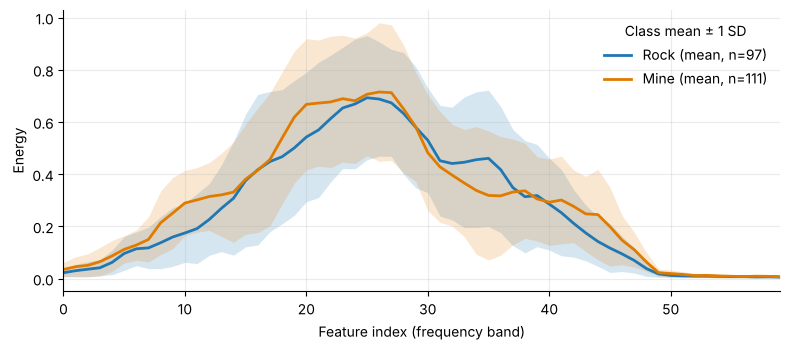

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.6))
xs = np.arange(60)
for lab, col, nm in [(1, BLUE, "Rock"), (0, ORANGE, "Mine")]:
    mu, sd = X[y == lab].mean(0), X[y == lab].std(0)
    ax.plot(xs, mu, color=col, lw=2, label=f"{nm} (mean, n={int((y == lab).sum())})")
    ax.fill_between(xs, mu - sd, mu + sd, color=col, alpha=.18, lw=0)
ax.set_xlim(0, 59)
ax.set_xlabel("Feature index (frequency band)")
ax.set_ylabel("Energy")
ax.grid(alpha=.25)
ax.legend(frameon=False, title="Class mean ± 1 SD")
save(fig, "f_classmeans_v3.png")

### Figure 3: evaluation protocols

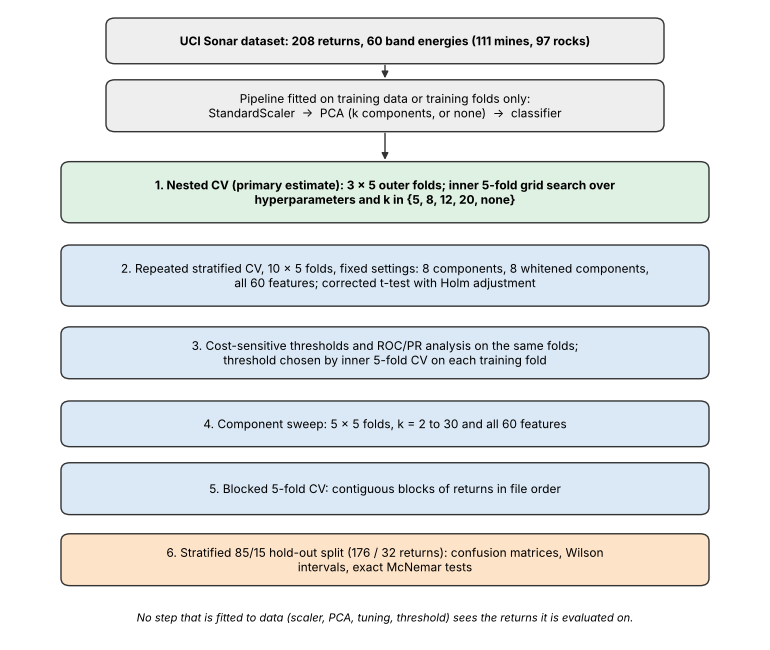

In [18]:
fig, ax = plt.subplots(figsize=(7.8, 6.6)); ax.set_xlim(0, 10); ax.set_ylim(0.3, 10.5); ax.axis("off")
LB, LO, GR, LG = "#dbe9f6", "#fde3c8", "#eeeeee", "#dff1e3"
def box(x, y, w, h, text, fc, bold=False, fs=8.6):
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle="round,pad=0.02,rounding_size=0.12", fc=fc, ec="#333333", lw=1))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else "normal")
def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color="#333333", lw=1))
box(5, 10.0, 7.4, 0.7, "UCI Sonar dataset: 208 returns, 60 band energies (111 mines, 97 rocks)", GR, True)
box(5, 8.95, 7.4, 0.8, "Pipeline fitted on training data or training folds only:\nStandardScaler  ->  PCA (k components, or none)  ->  classifier", GR)
arrow(5, 9.65, 5, 9.35)
box(5, 7.55, 8.6, 0.95, "1. Nested CV (primary estimate): 3 x 5 outer folds; inner 5-fold grid search over\nhyperparameters and k in {5, 8, 12, 20, none}", LG, True)
box(5, 6.2, 8.6, 0.95, "2. Repeated stratified CV, 10 x 5 folds, fixed settings: 8 components, 8 whitened components,\nall 60 features; corrected t-test with Holm adjustment", LB)
box(5, 4.95, 8.6, 0.8, "3. Cost-sensitive thresholds and ROC/PR analysis on the same folds;\nthreshold chosen by inner 5-fold CV on each training fold", LB)
box(5, 3.8, 8.6, 0.7, "4. Component sweep: 5 x 5 folds, k = 2 to 30 and all 60 features", LB)
box(5, 2.75, 8.6, 0.8, "5. Blocked 5-fold CV: contiguous blocks of returns in file order", LB)
box(5, 1.6, 8.6, 0.8, "6. Stratified 85/15 hold-out split (176 / 32 returns): confusion matrices, Wilson\nintervals, exact McNemar tests", LO)
for y1, y2 in [(8.55, 8.03)]:
    arrow(5, y1, 5, y2)
ax.text(5, 0.6, "No step that is fitted to data (scaler, PCA, tuning, threshold) sees the returns it is evaluated on.", ha="center", fontsize=8, style="italic")
save(fig, "f_workflow_v6.png")

### Figure 4: correlation on the training set

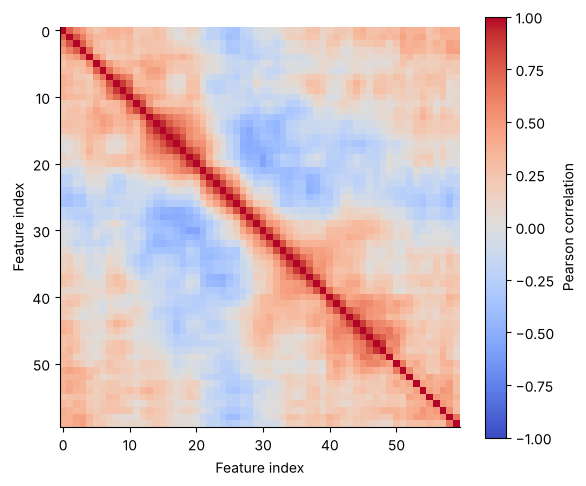

Lowest correlation: -0.559


In [19]:
C = np.corrcoef(X_train.T)
fig, ax = plt.subplots(figsize=(6.0, 5.0))
im = ax.imshow(C, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(0, 60, 10)); ax.set_yticks(range(0, 60, 10))
ax.set_xlabel("Feature index"); ax.set_ylabel("Feature index")
fig.colorbar(im, ax=ax, label="Pearson correlation")
save(fig, "f_corr_train_v3.png")
print(f"Lowest correlation: {C.min():.3f}")

### Figure 5: cumulative explained variance

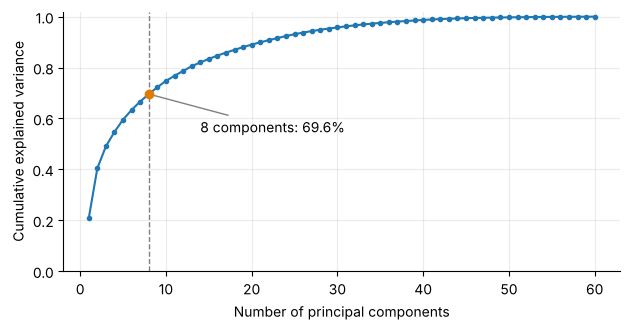

{1: np.float64(20.8), 2: np.float64(40.4), 8: np.float64(69.6), 15: np.float64(83.4), 20: np.float64(89.0), 30: np.float64(95.8)}


In [20]:
cum = np.cumsum(PCA().fit(Str).explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(range(1, 61), cum, marker="o", ms=3, color=BLUE)
ax.axvline(8, ls="--", color="gray", lw=1); ax.scatter([8], [cum[7]], color=ORANGE, zorder=5)
ax.annotate(f"8 components: {cum[7] * 100:.1f}%", (8, cum[7]), xytext=(14, cum[7] - 0.15), arrowprops=dict(arrowstyle="-", color="gray"))
ax.set_xlabel("Number of principal components"); ax.set_ylabel("Cumulative explained variance"); ax.set_ylim(0, 1.02)
ax.grid(alpha=.25)
save(fig, "f_pcavar_v3.png")
print({k: round(100 * cum[k - 1], 1) for k in [1, 2, 8, 15, 20, 30]})

### Figure 6: accuracy against the number of components

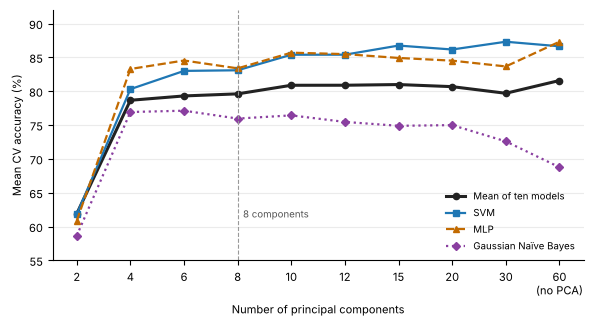

In [21]:
cols = list(sweep.columns)
xs = range(len(cols))
with plt.rc_context({"font.size": 8}):
    fig, ax = plt.subplots(figsize=(6.0, 3.3))
    for key, label, col, mk, ls, lw in [("MEAN", "Mean of ten models", "#222222", "o", "-", 2.2), ("SVM", "SVM", "#1f77b4", "s", "-", 1.6),
                                        ("MLP", "MLP", "#c26a00", "^", "--", 1.6), ("Gaussian Naive Bayes", "Gaussian Naïve Bayes", "#8a3fa0", "D", ":", 1.6)]:
        ax.plot(xs, sweep.loc[key].values, color=col, marker=mk, ms=4.5, lw=lw, ls=ls, label=label)
    ax.axvline(cols.index("8"), color="#999999", lw=0.8, ls="--")
    ax.text(cols.index("8") + 0.1, 61, "8 components", fontsize=7, color="#555555", va="bottom")
    ax.set_xticks(list(xs)); ax.set_xticklabels([c if c != "all60" else "60\n(no PCA)" for c in cols])
    ax.set_xlabel("Number of principal components"); ax.set_ylabel("Mean CV accuracy (%)"); ax.set_ylim(55, 92)
    ax.grid(axis="y", alpha=0.25); ax.legend(frameon=False, fontsize=7, loc="lower right")
    fig.tight_layout(); fig.savefig("figures/f_pcak_v6.png", dpi=300); plt.show()

### Figure 7: precision-recall curves for the mine class

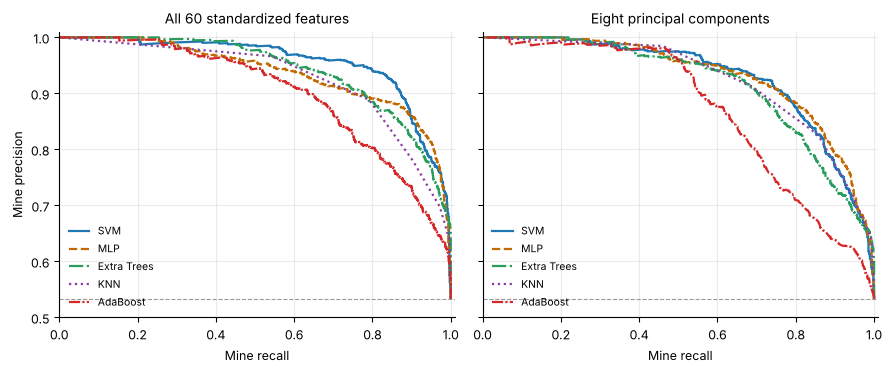

In [22]:
y_all = np.concatenate([y[te] for _, te in folds]) == 0
with plt.rc_context({"font.size": 9}):
    fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.8), sharey=True)
    show = [("SVM", "#1f77b4", "-"), ("MLP", "#c26a00", "--"), ("Extra Trees", "#2a9d5c", "-."), ("K-Nearest Neighbors", "#8a3fa0", ":"), ("AdaBoost", "#d62728", (0, (5, 1, 1, 1)))]
    for ax, tag, title in [(axes[0], "none", "All 60 standardized features"), (axes[1], "pca8", "Eight principal components")]:
        for name, col, ls in show:
            prec, rec, _ = precision_recall_curve(y_all, np.concatenate(probs[name, tag]))
            ax.plot(rec, prec, color=col, ls=ls, lw=1.6, label=name.replace("K-Nearest Neighbors", "KNN"))
        ax.axhline(y_all.mean(), color="#999999", lw=0.8, ls="--"); ax.set_title(title, fontsize=10)
        ax.set_xlabel("Mine recall"); ax.set_xlim(0, 1.01); ax.set_ylim(0.5, 1.01); ax.grid(alpha=0.25); ax.legend(frameon=False, fontsize=7.5, loc="lower left")
    axes[0].set_ylabel("Mine precision")
    fig.tight_layout(); fig.savefig("figures/f_pr_v6.png", dpi=300); plt.show()

### Figure 8: confusion matrices on the hold-out split

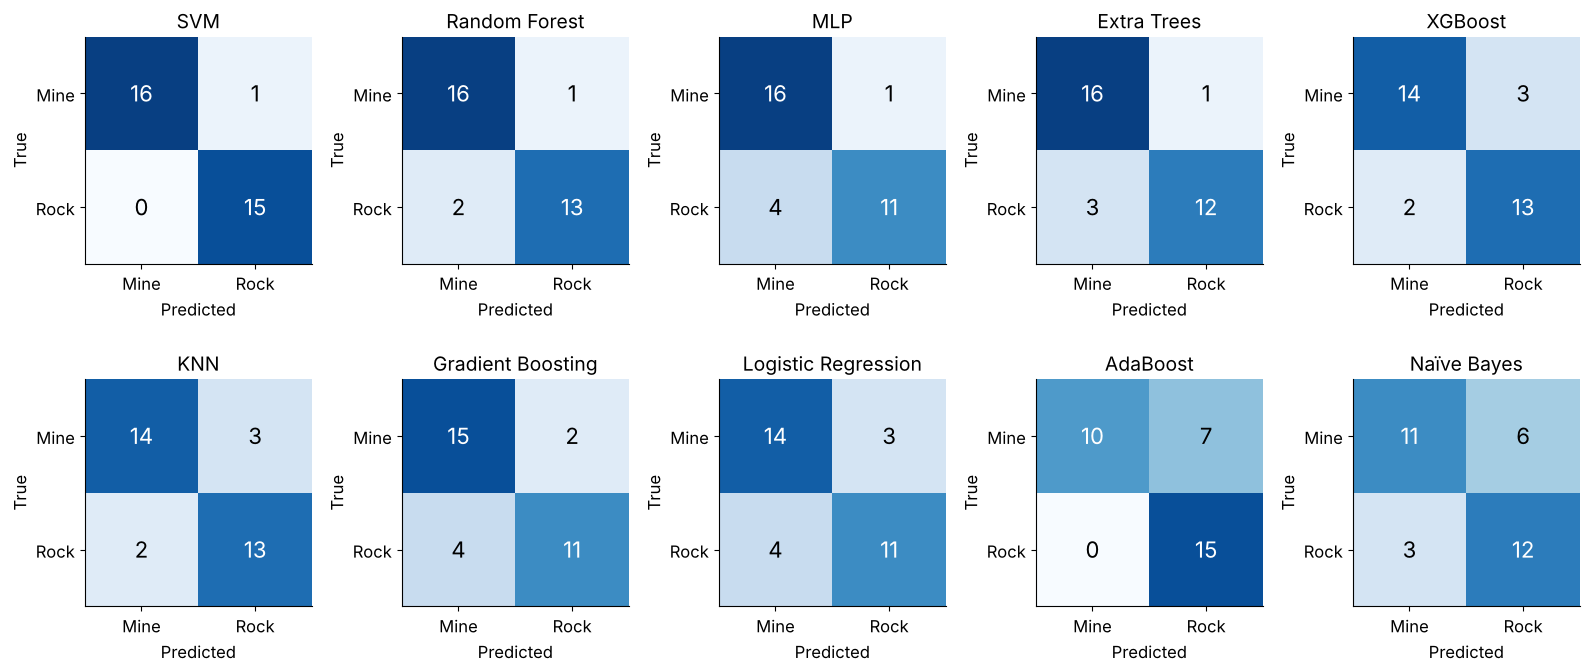

In [23]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, n in zip(axes.ravel(), make_models()):
    cm = confusion_matrix(y_test, pred_pca[n], labels=[0, 1])
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=17)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > 8 else "black", fontsize=16)
    ax.set_xticks([0, 1], ["Mine", "Rock"], fontsize=12); ax.set_yticks([0, 1], ["Mine", "Rock"], fontsize=12)
    ax.set_title(n.replace("Gaussian Naive Bayes", "Naïve Bayes").replace("K-Nearest Neighbors", "KNN"), fontsize=14)
    ax.set_xlabel("Predicted", fontsize=12); ax.set_ylabel("True", fontsize=12)
save(fig, "f_confusion_v6.png", 200)